# L1 reordering — does repairing the order actually help?

`ReorderingInsertionPolicy` adds a relocate-repair pass to
`WindowInsertionPolicy`: eject one request, put it back at its cheapest
feasible slot, keep the move only if it strictly lowers total passenger time.
This notebook measures whether that is worth having.

Three columns, all at `commitment=0` on the campus map:

| Column | Policy |
| --- | --- |
| **L0** | `WindowInsertionPolicy` — insert only, order frozen once placed |
| **L1 (no retry)** | repair pass only; reordering measured in isolation |
| **L1 (retry)** | repair, then re-offer the requests refused earlier in the call |

## Why this runs its own L0 column

`baseline-c0.ipynb` also measures `Window 900s` at `commitment=0`, so an L0
column here looks redundant. It is not, for two reasons.

**Pairing.** Every comparison in this project has been paired by seed, which is
what turned a marginal interval overlap into p = 0.002 for the commitment
change. Comparing L1 here against an L0 run elsewhere — different trial count,
different seed set — would be unpaired and far less sensitive.

**Instrumentation.** `baseline-c0` runs plain policies and therefore records no
rejection counts. Rejections are the *primary* readout below, so L0 has to be
instrumented the same way L1 is.

The two notebooks are complementary rather than overlapping, and can run
concurrently: separate kernels are separate processes with their own RNG
state.

## The questions, and what would settle them

### Q1 — does reordering reduce rejections? (primary)

`reordering-headroom.ipynb` found **54% of insertion attempts rejected** on the
deadline alone, against a median schedule of 13 requests. A rejection means "no
feasible slot exists *in the current frozen order*" — not "this request is
unservable". Repairing the order is exactly the mechanism that could convert
some of those into acceptances.

This is measured first and weighted most, because it reads the mechanism
directly. The KPIs are downstream of it and noisier.

!!! warning "Two refusal metrics, and why one alone is not enough"
    L1 calls `_best_insertion` from three places — first-pass insertion,
    relocation, and retry — so pooling them would compare L0's first-pass
    attempts against a denominator four to five times larger for L1.
    Relocations almost always succeed, which drags the pooled rate down and
    manufactures an improvement that is pure bookkeeping. A smoke run showed
    exactly that: 53% against 11%, entirely an artefact.

    So the table reports **share of waiting requests left unscheduled**, which
    depends on no internal call structure and is therefore the safer headline,
    alongside the **first-pass rejection rate**, which is directly comparable
    to the 54% in `reordering-headroom.ipynb`. They should move together; if
    they disagree, trust the first.

- **Both fall materially** → the repair pass is fitting more work into the
  same service window.
- **Unchanged** → either repair rarely finds improvements, or the improvements
  it finds do not translate into usable slack. Either way L1 is not earning
  its cost, and L2 is unlikely to be worth attempting.

### Q2 — does it reach the KPIs?

- **Mean wait and/or mean ride improve** → the payoff is real.
- **Rejections fall but KPIs do not** → reordering improves the policy's own
  objective without improving service. That is a genuine negative result and
  worth reporting as one.

Coverage is *not* the metric to watch. Roughly 9% of rejections are terminal
(≈189 rejections per trial against ≈17 requests lost), and the W900 ceiling is
passenger patience rather than the algorithm — `W1350` reaches 99.3% served.
Expect wait and ride.

!!! danger "Watch max ride"
    `_cost` is total passenger time, indifferent to how that total is
    distributed. A large search space lets the repair pass shave the sum by
    lengthening one rider's trip a lot. If max ride rises while the means
    fall, the objective needs a fairness term.

### Q3 — what does the retry step add?

- **L1 (retry) beats L1 (no retry)** on served fraction or wait → re-offering
  refused requests within the same call earns its place as the default.
- **No difference** → the deferred path already captures it (a rejected request
  stays `PENDING` and is retried on the next arrival anyway), and the default
  should flip to `False` for the simpler behaviour.

### Q4 — what does it cost?

L1 was predicted at roughly **3.7×** the insertion work, on a base under 7 ms
per plan call. The cost-check cell measures it. Substantially worse than that
would move profiling `_best_insertion` up the priority list — it recomputes
the whole arrival timeline for each of ~210 candidate slot pairs, and
`Schedule.forward_slack` exists precisely to avoid that.

In [1]:
%matplotlib inline
# Static comparison charts only, so the inline backend is all we need.

import statistics
import time
from collections import defaultdict
from typing import Callable

import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

from src.algorithm.DispatchPolicy import BusState, DispatchPolicy
from src.algorithm.ReorderingInsertionPolicy import ReorderingInsertionPolicy
from src.algorithm.RequestPool import Request
from src.algorithm.Schedule import Schedule
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import (
    ComparisonSummary,
    TrialResult,
    plot_kpi_bars,
    run_trial,
    summarize_comparison,
)
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.TransitGraph import TransitGraph
from src.map.graph import PlanarStreetGraph


class _RejectionCounting:
    """
    Mixin recording how often the policy refused to schedule a request.

    Applies to any WindowInsertionPolicy descendant. Every override counts and
    delegates straight up, so behaviour is unchanged.

    **The subtlety this exists to handle.** ``_best_insertion`` is the one
    place a refusal can be observed, but L1 calls it from three different
    places: inserting a newly seen request, re-placing one during a
    relocation, and re-offering one during the retry step. Counting all three
    together would compare L0's first-pass attempts against a denominator
    four to five times larger for L1 — a relocation almost always succeeds,
    so the pooled rate collapses and looks like a huge improvement that is
    purely an artefact of the extra calls. Each call site is therefore tallied
    separately, and only the first-pass numbers are compared across columns.

    Two measures of refusal are kept:

    - **first-pass rejections** — the mechanism, directly comparable to the
      54% measured in ``reordering-headroom.ipynb``;
    - **requests left unscheduled** — how many waiting riders the policy
      declined to plan for, summed over planning calls. This one depends on
      no internal call structure at all, so it stays valid however the policy
      is implemented, and is the safer headline of the two.

    Counts live on the instance and are read back through ``stats()`` rather
    than accumulating into a module-level dict. One policy is built per trial,
    so run totals are a sum over instances — and unlike a global, this keeps
    working if trials are ever run in separate processes.
    """

    def __init__(self, *args: object, **kwargs: object) -> None:
        """Forward every argument to the policy being wrapped."""
        super().__init__(*args, **kwargs)
        self._counts: dict[str, float] = {
            "plan_calls": 0.0,
            "offered": 0.0,
            "left_unscheduled": 0.0,
            "insertion_attempts": 0.0,
            "rejections": 0.0,
            "plans_with_rejection": 0.0,
            "relocation_attempts": 0.0,
            "relocation_failures": 0.0,
            "retry_insertions": 0.0,
        }
        # Which call site _best_insertion is currently serving.
        self._context = "insertion"
        self._rejected_this_call = 0

    def plan(self, state: BusState, n_stops: int) -> list[str]:
        """Plan normally, then record who was left waiting."""
        self._context = "insertion"
        self._rejected_this_call = 0
        offered = {request.id for request in state.pending_requests}

        route = super().plan(state, n_stops)

        self._counts["plan_calls"] += 1
        self._counts["offered"] += len(offered)
        self._counts["left_unscheduled"] += len(
            offered - self.schedule.owners()
        )
        if self._rejected_this_call:
            self._counts["plans_with_rejection"] += 1
        return route

    def _best_insertion(
        self, schedule: Schedule, request: Request, state: BusState
    ) -> Schedule | None:
        """Insert normally, then tally the outcome against its call site."""
        result = super()._best_insertion(schedule, request, state)
        if self._context == "relocation":
            self._counts["relocation_attempts"] += 1
            if result is None:
                self._counts["relocation_failures"] += 1
        elif self._context == "retry":
            self._counts["retry_insertions"] += 1
        else:
            self._counts["insertion_attempts"] += 1
            if result is None:
                self._counts["rejections"] += 1
                self._rejected_this_call += 1
        return result

    def _relocate_pair(
        self, schedule: Schedule, request: Request, state: BusState
    ) -> Schedule | None:
        """Mark the re-placement so it is not counted as a first insertion."""
        self._context = "relocation"
        try:
            return super()._relocate_pair(schedule, request, state)
        finally:
            self._context = "insertion"

    def _retry(self, schedule: Schedule, state: BusState) -> Schedule:
        """Mark re-offers so they are not counted as first insertions."""
        self._context = "retry"
        try:
            return super()._retry(schedule, state)
        finally:
            self._context = "insertion"

    def stats(self) -> dict[str, float]:
        """
        Merge these counters with any the wrapped policy reports.
        :return: Counter name to value.
        """
        merged = dict(self._counts)
        inherited = getattr(super(), "stats", None)
        if inherited is not None:
            merged.update(inherited())
        return merged


class CountingL0(_RejectionCounting, WindowInsertionPolicy):
    """Insert-only baseline, instrumented."""


class CountingL1(_RejectionCounting, ReorderingInsertionPolicy):
    """Relocate-repair policy, instrumented."""


# Every policy built during the run, per column, so stats() can be summed
# afterwards. Cleared by the run cell. A few hundred small objects.
INSTANCES: dict[str, list[object]] = defaultdict(list)


def make_factory(
    label: str,
    policy_class: type,
    **kwargs: object,
) -> Callable[[TransitGraph], DispatchPolicy]:
    """
    Build a policy factory that registers what it builds.

    A named closure rather than a lambda, so the late-binding trap that bites
    list comprehensions cannot arise.
    :param label: Column label the instances are filed under.
    :param policy_class: Policy to construct.
    :param kwargs: Constructor arguments for that policy.
    :return: Callable taking a TransitGraph and returning a policy.
    """
    def factory(graph: TransitGraph) -> DispatchPolicy:
        policy = policy_class(graph, **kwargs)
        INSTANCES[label].append(policy)
        return policy
    return factory


# Trials per column. The effects here are read from paired differences, which
# resolve far more than independent intervals; raise it if Q3 comes out too
# close to call.
N_TRIALS = 200
BASE_SEED = 0
WINDOW_S = 900.0

# run_trial kwargs matching every previous campus experiment. NOTE: max_wait_s
# here is the *backend's abandonment threshold*, a different quantity from the
# policy's service window above; they coincide at 900s deliberately.
# commitment is passed explicitly even though 0 is now the default, because it
# is load-bearing for these results.
LOAD = dict(
    max_requests=200, capacity=40, max_wait_s=900.0, commitment=0,
)

LABEL_L0 = "L0 insert-only"
LABEL_L1_PLAIN = "L1 no retry"
LABEL_L1_RETRY = "L1 retry"
COLUMNS = [LABEL_L0, LABEL_L1_PLAIN, LABEL_L1_RETRY]

POLICIES: list[tuple[str, Callable[[TransitGraph], DispatchPolicy]]] = [
    (LABEL_L0, make_factory(LABEL_L0, CountingL0, max_wait_s=WINDOW_S)),
    (LABEL_L1_PLAIN, make_factory(
        LABEL_L1_PLAIN, CountingL1,
        max_wait_s=WINDOW_S, retry_rejected=False,
    )),
    (LABEL_L1_RETRY, make_factory(
        LABEL_L1_RETRY, CountingL1,
        max_wait_s=WINDOW_S, retry_rejected=True,
    )),
]

## 1. Shared map

Identical to every previous sweep — same `MAP_SEED`, same campus
configuration — so the L0 column here is comparable to `Window 900s` at
`commitment=0` elsewhere.

In [2]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds=17,
    bounds=(0.0, 0.0, 2000.0, 2000.0),
    seed=MAP_SEED,
    stop_density=0.5,
)

provider = PlanarMapProvider(graph)
print(f"{len(provider.get_stops())} bus stops on this map")

21 bus stops on this map


## 2. Cost check

This is Q4, and it also decides whether `N_TRIALS` above is sensible. L1 was
predicted at roughly 3.7× L0.

If `baseline-c0.ipynb` is still running in another kernel, both timings here
are inflated by CPU contention — the *ratio* stays meaningful, the absolute
seconds do not.

In [3]:
probe_costs: dict[str, float] = {}
for label, factory in POLICIES:
    start = time.perf_counter()
    run_trial(
        policy_factory=factory, graph=graph, seed=BASE_SEED,
        silent=True, **LOAD,
    )
    probe_costs[label] = time.perf_counter() - start

INSTANCES.clear()  # discard the probes' policies

baseline = probe_costs[LABEL_L0]
projected_s = N_TRIALS * sum(probe_costs.values())
display(Markdown("\n".join(
    [f"- One trial, **{label}**: {cost:.1f} s "
     f"({cost / baseline:.1f}x L0)"
     for label, cost in probe_costs.items()]
    + ["",
       f"Projected total ({N_TRIALS} trials x {len(COLUMNS)} columns): "
       f"**{projected_s / 60:.1f} min**"]
)))

- One trial, **L0 insert-only**: 1.3 s (1.0x L0)
- One trial, **L1 no retry**: 4.5 s (3.4x L0)
- One trial, **L1 retry**: 5.1 s (3.9x L0)

Projected total (200 trials x 3 columns): **36.2 min**

## 3. The run

One call, so all three columns share `base_seed` and trial *i* faces the same
demand sequence in each — which is what makes the paired differences below
valid.

In [4]:
INSTANCES.clear()  # re-running this cell replaces the tallies

summary = summarize_comparison(
    policies=POLICIES,
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    **LOAD,
)

L0 insert-only:   0%|          | 0/200 [00:00<?, ?it/s]

L1 no retry   :   0%|          | 0/200 [00:00<?, ?it/s]

L1 retry      :   0%|          | 0/200 [00:00<?, ?it/s]

## 4. The mechanism (Q1)

Summed over every policy built during the run. **The rejection rate is the
headline number**; everything else on this table explains it.

In [5]:
def totals(label: str) -> dict[str, float]:
    """
    Sum the counters of every policy built for one column.
    :param label: Column label.
    :return: Counter name to run total, empty if the column never ran.
    """
    merged: dict[str, float] = defaultdict(float)
    for policy in INSTANCES[label]:
        for key, value in policy.stats().items():
            merged[key] += value
    return dict(merged)


def rate(numerator: float, denominator: float) -> float:
    """
    Percentage ratio degrading to NaN rather than raising.
    :param numerator: Count of events.
    :param denominator: Count of opportunities.
    :return: Percentage, or NaN when denominator is zero.
    """
    if not denominator:
        return float("nan")
    return 100.0 * numerator / denominator


def count(totals_of_column: dict[str, float], key: str) -> str:
    """
    Format one counter as a thousands-separated whole number.
    :param totals_of_column: Run totals for one column.
    :param key: Counter name.
    :return: The formatted count, 0 when the counter is absent.
    """
    return f"{totals_of_column.get(key, 0.0):,.0f}"


def ratio_of(
    totals_of_column: dict[str, float], numerator: str, denominator: str
) -> str:
    """
    Format two counters as a percentage of one another.
    :param totals_of_column: Run totals for one column.
    :param numerator: Counter naming the events.
    :param denominator: Counter naming the opportunities.
    :return: The formatted percentage.
    """
    value = rate(
        totals_of_column.get(numerator, 0.0),
        totals_of_column.get(denominator, 0.0),
    )
    return f"{value:.1f} %"


def accepted_of(
    totals_of_column: dict[str, float], operator: str
) -> str:
    """
    Format one relocation operator's acceptances against its attempts.
    :param totals_of_column: Run totals for one column.
    :param operator: Counter prefix, "pair" or "dropoff".
    :return: "accepted / attempted".
    """
    return (
        f"{totals_of_column.get(f'{operator}_accepted', 0.0):,.0f}"
        f" / {totals_of_column.get(f'{operator}_attempts', 0.0):,.0f}"
    )


TOTALS = {label: totals(label) for label in COLUMNS}

ROWS: list[tuple[str, Callable[[dict[str, float]], str]]] = [
    ("Plan calls", lambda t: count(t, "plan_calls")),
    ("Waiting requests offered", lambda t: count(t, "offered")),
    ("Left unscheduled", lambda t: count(t, "left_unscheduled")),
    ("**Share left unscheduled**",
     lambda t: f"**{ratio_of(t, 'left_unscheduled', 'offered')}**"),
    ("First-pass insertion attempts",
     lambda t: count(t, "insertion_attempts")),
    ("First-pass rejections", lambda t: count(t, "rejections")),
    ("**First-pass rejection rate**",
     lambda t: f"**{ratio_of(t, 'rejections', 'insertion_attempts')}**"),
    ("Plan calls with >= 1 rejection",
     lambda t: ratio_of(t, "plans_with_rejection", "plan_calls")),
    ("Pair relocations accepted / tried",
     lambda t: accepted_of(t, "pair")),
    ("Dropoff relocations accepted / tried",
     lambda t: accepted_of(t, "dropoff")),
    ("Retry admitted / attempted",
     lambda t: f"{t.get('retry_admitted', 0.0):,.0f}"
               f" / {t.get('retry_attempts', 0.0):,.0f}"),
    ("Total cost saved by repair (s)",
     lambda t: count(t, "cost_improvement")),
    ("(diagnostic) relocations that found no slot",
     lambda t: count(t, "relocation_failures")),
]

lines = [
    "| Measurement | " + " | ".join(COLUMNS) + " |",
    "| --- | " + " | ".join("---" for _ in COLUMNS) + " |",
]
for row_label, extract in ROWS:
    lines.append(
        f"| {row_label} | "
        + " | ".join(extract(TOTALS[column]) for column in COLUMNS)
        + " |"
    )
display(Markdown("\n".join(lines)))

| Measurement | L0 insert-only | L1 no retry | L1 retry |
| --- | --- | --- | --- |
| Plan calls | 40,559 | 41,788 | 41,782 |
| Waiting requests offered | 288,609 | 292,200 | 291,974 |
| Left unscheduled | 32,441 | 31,099 | 30,812 |
| **Share left unscheduled** | **11.2 %** | **10.6 %** | **10.6 %** |
| First-pass insertion attempts | 68,097 | 66,941 | 66,649 |
| First-pass rejections | 32,441 | 31,099 | 31,075 |
| **First-pass rejection rate** | **47.6 %** | **46.5 %** | **46.6 %** |
| Plan calls with >= 1 rejection | 49.6 % | 47.1 % | 47.0 % |
| Pair relocations accepted / tried | 0 / 0 | 10,033 / 261,101 | 10,059 / 260,899 |
| Dropoff relocations accepted / tried | 0 / 0 | 3,872 / 289,101 | 3,884 / 289,139 |
| Retry admitted / attempted | 0 / 0 | 0 / 0 | 263 / 31,074 |
| Total cost saved by repair (s) | 0 | 2,914,309 | 2,920,549 |
| (diagnostic) relocations that found no slot | 0 | 0 | 0 |

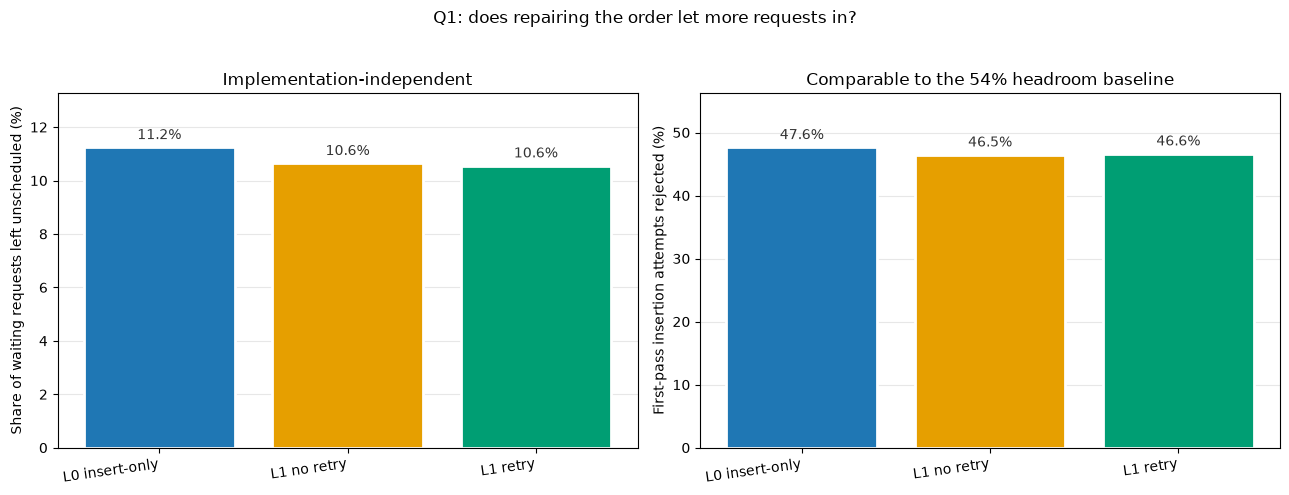

In [6]:
# Fixed categorical order, validated for CVD separation. Values are labelled
# directly, which is also the relief the amber needs on a light page.
COLUMN_COLOUR = {
    LABEL_L0: "#1f77b4",
    LABEL_L1_PLAIN: "#e69f00",
    LABEL_L1_RETRY: "#009e73",
}

positions = list(range(len(COLUMNS)))
PANELS = [
    ("Share of waiting requests left unscheduled (%)",
     "left_unscheduled", "offered",
     "Implementation-independent"),
    ("First-pass insertion attempts rejected (%)",
     "rejections", "insertion_attempts",
     "Comparable to the 54% headroom baseline"),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (ylabel, numerator, denominator, subtitle) in zip(axes, PANELS):
    values = [
        rate(TOTALS[c].get(numerator, 0.0), TOTALS[c].get(denominator, 0.0))
        for c in COLUMNS
    ]
    ax.bar(positions, values,
           color=[COLUMN_COLOUR[c] for c in COLUMNS],
           edgecolor="white", linewidth=2)
    for position, value in zip(positions, values):
        ax.annotate(f"{value:.1f}%", xy=(position, value), xytext=(0, 6),
                    textcoords="offset points", ha="center", fontsize=10,
                    color="0.2")
    ax.set_xticks(positions)
    ax.set_xticklabels(COLUMNS, rotation=8, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_title(subtitle)
    ax.grid(True, axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.margins(y=0.18)

fig.suptitle("Q1: does repairing the order let more requests in?")
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.95))
plt.show()

## 5. Service quality (Q2, Q3)

Paired per-trial differences against L0. Positive is better for served
fraction; negative is better for every timing row.

In [7]:
def paired_delta(
    baseline: list[TrialResult],
    treatment: list[TrialResult],
    extract: Callable[[TrialResult], float | None],
) -> tuple[float, float, float]:
    """
    Mean per-trial difference (treatment - baseline) with a CI and a p-value.

    Trials are paired by index, which is meaningful because every column ran
    in one summarize_comparison call, so trial i faced the same demand
    sequence throughout.
    :param baseline: Per-trial results for the reference column.
    :param treatment: Per-trial results for the column being tested.
    :param extract: Maps a TrialResult to the scalar being compared, or None
        when that trial does not define it.
    :return: (mean difference, 95% CI half-width, two-sided paired p-value).
        The last two are NaN with fewer than two usable pairs.
    """
    pairs = [
        (before, after)
        for base_trial, treat_trial in zip(baseline, treatment)
        if (before := extract(base_trial)) is not None
        and (after := extract(treat_trial)) is not None
    ]
    if not pairs:
        return float("nan"), float("nan"), float("nan")

    differences = [after - before for before, after in pairs]
    mean_difference = statistics.fmean(differences)
    if len(differences) < 2:
        return mean_difference, float("nan"), float("nan")

    half_width = (
        stats.t.ppf(0.975, len(differences) - 1)
        * statistics.stdev(differences)
        / len(differences) ** 0.5
    )
    p_value = float(stats.ttest_rel(
        [after for _, after in pairs],
        [before for before, _ in pairs],
    ).pvalue)
    return mean_difference, half_width, p_value


def served_pp(trial: TrialResult) -> float | None:
    """
    Served fraction as percentage points, or None when undefined.
    :param trial: One trial's results.
    :return: Served fraction x 100, or None.
    """
    if trial.kpi.served_fraction is None:
        return None
    return 100.0 * trial.kpi.served_fraction


# (display name, extractor, direction that counts as an improvement)
_MetricSpec = tuple[str, Callable[[TrialResult], float | None], str]

METRICS: list[_MetricSpec] = [
    ("Served (pp)", served_pp, "higher"),
    ("Mean wait (s)", lambda r: r.kpi.mean_wait_time, "lower"),
    ("P90 wait (s)", lambda r: r.kpi.p90_wait_time, "lower"),
    ("Mean ride (s)", lambda r: r.kpi.mean_ride_time, "lower"),
    ("Max ride (s)",
     lambda r: max(r.ride_times) if r.ride_times else None, "lower"),
]

lines = [
    "| Metric | L0 | "
    + " | ".join(f"{c} (delta vs L0)" for c in COLUMNS[1:]) + " |",
    "| --- | --- | " + " | ".join("---" for _ in COLUMNS[1:]) + " |",
]
for metric_name, extract, better in METRICS:
    baseline_values = [
        value for trial in summary.results[LABEL_L0]
        if (value := extract(trial)) is not None
    ]
    cells = [f"{statistics.fmean(baseline_values):.1f}"]
    for column in COLUMNS[1:]:
        delta, half_width, p_value = paired_delta(
            summary.results[LABEL_L0], summary.results[column], extract
        )
        improved = delta > 0 if better == "higher" else delta < 0
        mark = "**" if p_value < 0.05 and improved else ""
        cells.append(
            f"{mark}{delta:+.1f} ± {half_width:.1f}{mark} (p={p_value:.3f})"
        )
    lines.append(f"| {metric_name} | " + " | ".join(cells) + " |")
display(Markdown("\n".join(lines)))
display(Markdown(
    "*Bold marks a difference both significant at p < 0.05 and in the "
    "favourable direction, so a significant regression cannot hide as a "
    "bold cell.*"
))

| Metric | L0 | L1 no retry (delta vs L0) | L1 retry (delta vs L0) |
| --- | --- | --- | --- |
| Served (pp) | 93.3 | **+0.8 ± 0.3** (p=0.000) | **+0.8 ± 0.3** (p=0.000) |
| Mean wait (s) | 465.7 | **-9.3 ± 3.2** (p=0.000) | **-9.6 ± 3.2** (p=0.000) |
| P90 wait (s) | 849.6 | **-9.3 ± 2.8** (p=0.000) | **-9.2 ± 2.8** (p=0.000) |
| Mean ride (s) | 523.3 | **-63.7 ± 6.9** (p=0.000) | **-63.7 ± 7.0** (p=0.000) |
| Max ride (s) | 2617.4 | **-291.4 ± 108.3** (p=0.000) | **-295.8 ± 108.8** (p=0.000) |

*Bold marks a difference both significant at p < 0.05 and in the favourable direction, so a significant regression cannot hide as a bold cell.*

| Property | L0 insert-only | L1 no retry | L1 retry |
| --- | --- | --- | --- |
| Fulfilled requests | 185.5 (±1.0%) | 187.0 (±1.0%) | 187.1 (±1.0%) |
| Cancelled requests | 13.5 (±4.5%) | 12.0 (±4.9%) | 11.9 (±4.9%) |
| Mean wait time | 465.7 s (±1.2%) | 456.4 s (±1.2%) | 456.0 s (±1.2%) |
| P90 wait time | 849.6 s (±1.0%) | 840.2 s (±1.0%) | 840.3 s (±1.0%) |
| Mean ride time | 523.3 s (±1.6%) | 459.6 s (±1.4%) | 459.6 s (±1.4%) |
| Fulfillment rate | 93.3 % (±0.3%) | 94.0 % (±0.3%) | 94.0 % (±0.3%) |
| Served fraction | 93.3 % (±0.3%) | 94.0 % (±0.3%) | 94.0 % (±0.3%) |
| Throughput | 0.9 req/min (±1.0%) | 0.9 req/min (±1.0%) | 0.9 req/min (±1.0%) |
| Tick snapshots | 13117.0 (±1.0%) | 13025.2 (±1.0%) | 13025.4 (±1.0%) |
| Fulfilled (wait samples) | 185.5 (±1.0%) | 187.0 (±1.0%) | 187.1 (±1.0%) |
| Min wait time | 5.8 s (±14.6%) | 5.2 s (±14.5%) | 5.2 s (±14.5%) |
| Max wait time | 893.0 s (±1.0%) | 892.9 s (±1.0%) | 892.8 s (±1.0%) |
| Min ride time | 6.1 s (±8.4%) | 6.0 s (±8.4%) | 6.0 s (±8.4%) |
| Max ride time | 2617.4 s (±3.2%) | 2326.1 s (±3.6%) | 2321.6 s (±3.6%) |

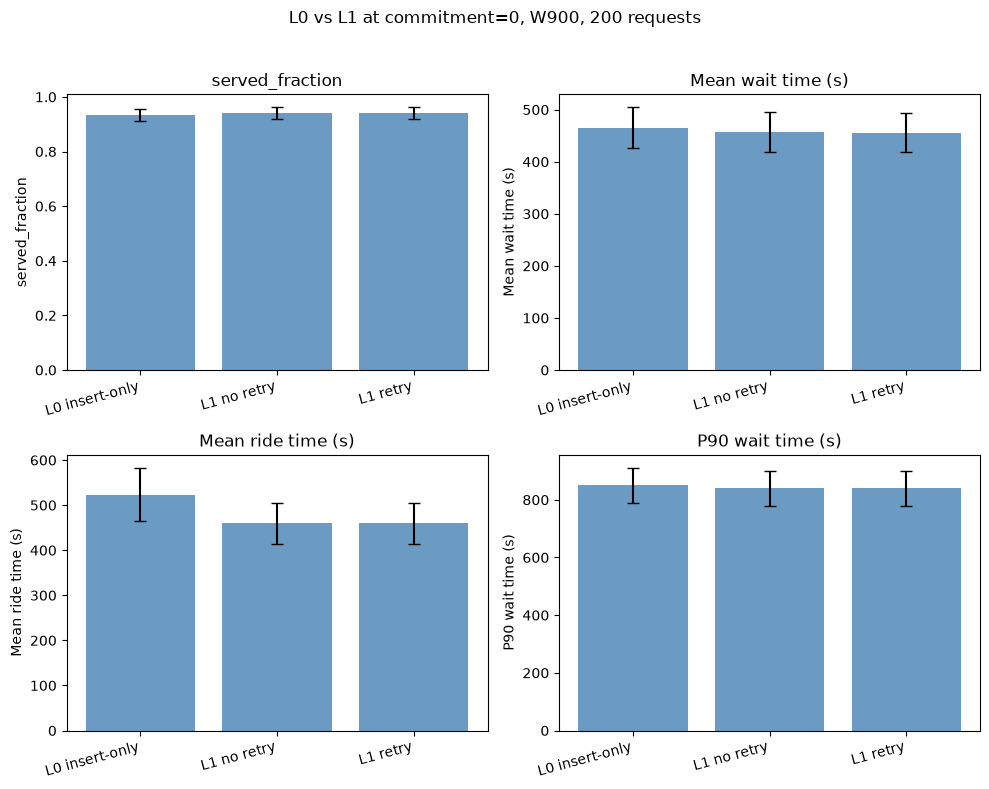

In [8]:
plot_kpi_bars(
    summary.results,
    fields=["served_fraction", "mean_wait_time",
            "mean_ride_time", "p90_wait_time"],
    title="L0 vs L1 at commitment=0, W900, 200 requests",
)
display(Markdown(summary.markdown))

## What to look for

**Q1 — the refusal metrics.** L0's *first-pass* rejection rate should land
near the 47% measured at `commitment=0` in `reordering-headroom.ipynb`; treat
a large discrepancy as a reason to stop and reconcile before reading anything
else. Read the two panels together — the left one is implementation-independent
and wins any disagreement.

- *Falls materially in both L1 columns* → the repair pass is packing more work
  into the same service window. This is the result the whole direction rests
  on.
- *Unchanged* → L1 is not earning its cost. Before abandoning the ladder,
  check "pair relocations accepted / tried": near-zero acceptances means the
  operator is not finding improvements at all, whereas many acceptances with
  no rejection change means it is improving cost without creating usable
  slack. Those point at different fixes — the first at the operator, the
  second at the objective.

**Q2 — service quality.** Read mean wait and mean ride first; coverage is
patience-bound at this window and has little room.

- *Rejections fall and timings improve* → L1 works, and L2 (ruin & recreate)
  becomes worth the investment.
- *Rejections fall, timings flat* → reordering improves the policy's internal
  objective without improving service. A real negative result: report it as
  one rather than hunting for a metric that moves.
- *Max ride rises while means fall* → the fairness problem flagged above.
  `_cost` would need a per-rider penalty before L1 is adopted.

**Q3 — the retry step.** Compare the two L1 columns against each other, not
just against L0.

- *Retry clearly ahead* → keep it as the default.
- *Indistinguishable* → the next-arrival path already captures it; flip the
  default to `False` for simpler behaviour and one less thing to explain.
- *Retry behind on ride time* → it is admitting marginal requests that detour
  the bus. That is the same coverage-versus-ride trade the service window
  sweep found, reappearing one level down.

**Q4 — cost.** The ratio printed by the cost check. Anything far above ~4×
makes profiling `_best_insertion` the better next move than L2.

### A caveat on reproducibility

Set `PYTHONHASHSEED=0` before launching Jupyter. Running this concurrently
with another experiment is safe — separate kernels are separate processes with
independent RNG state — but it does inflate the cost-check timings.